# Project 19: Error Analysis & Model Debugging

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Model performance plateaus. Task: Perform systematic error analysis; Identify failure modes; Propose data or model fixes and validate them

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** When accuracy plateaus, the next step is not a bigger model — it is looking at which examples fail, and why. This notebook does that systematically, then validates one fix.

## Part 1 — Introduction

Failure modes are derived from the actual confusion matrix and error rates by group in this run. No failure mode is claimed without a printed number behind it.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Baseline errors and confusion

Baseline accuracy: 0.8994
              precision    recall  f1-score   support

           0       0.91      0.96      0.94      2812
           1       0.94      0.86      0.90      1808
           2       0.83      0.93      0.88      1021
           3       0.85      0.68      0.76       609

    accuracy                           0.90      6250
   macro avg       0.88      0.86      0.87      6250
weighted avg       0.90      0.90      0.90      6250

Confusion matrix rows=true, cols=pred:
 [[2711  101    0    0]
 [ 261 1547    0    0]
 [   0    0  946   75]
 [   0    0  192  417]]


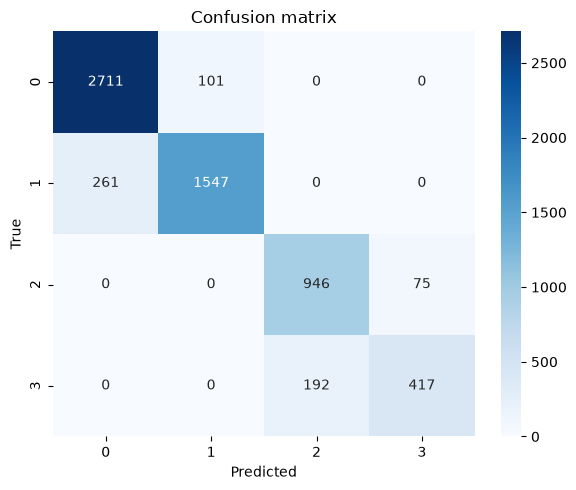

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
df=df_full.sample(n=25000, random_state=42).reset_index(drop=True)
def quadrant(b):
    if b>=315 or b<45: return "North"
    if b<135: return "East"
    if b<225: return "South"
    return "West"
df["proxy_group"]=df["Wind_Bearing"].apply(quadrant)
df["temp_band"]=pd.cut(df["temp_mean(c)"], bins=[-100,5,15,25,100], labels=["cold","mild","warm","hot"])
Xtr,Xte,ytr,yte,gtr,gte,btr,bte=train_test_split(df[FEATURES], df[TARGET], df["proxy_group"], df["temp_band"], test_size=0.25, random_state=42, stratify=df[TARGET])
m=RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1); m.fit(Xtr,ytr); pred=m.predict(Xte)
print("Baseline accuracy:", round(accuracy_score(yte,pred),4)); print(classification_report(yte,pred,zero_division=0))
cm=confusion_matrix(yte,pred,labels=[0,1,2,3]); print("Confusion matrix rows=true, cols=pred:\n", cm)
plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[0,1,2,3], yticklabels=[0,1,2,3]); plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.tight_layout(); plt.show()

## Part 4 — Error breakdown by group and proposed fix

In [3]:
err=(yte.values!=pred)
for name, groups in [("Wind quadrant", gte.values), ("Temp band", bte.values.astype(str))]:
    s=pd.DataFrame({"group":groups,"error":err}).groupby("group")["error"].agg(["mean","count"]); print(name, "error rate:\n", s.round(4).to_string())
    print("---")
# Most confused pair (off-diagonal)
pairs=[]
for i in range(4):
    for j in range(4):
        if i!=j: pairs.append((cm[i,j], i, j))
pairs.sort(reverse=True); print("Most confused pairs (count, true, pred):", pairs[:3])
# Feature means: correct vs incorrect
Xte_df=pd.DataFrame(Xte, columns=FEATURES); Xte_df["error"]=err
print("Mean features, correct vs incorrect:\n", Xte_df.groupby("error").mean().round(3).T.to_string())
# Fix 1: class_weight balanced; Fix 2: add temp_range feature
df["temp_range"]=df["temp_max(c)"]-df["temp_min(c)"]
FEATS2=FEATURES+["temp_range"]
Xtr2,Xte2,ytr2,yte2=train_test_split(df[FEATS2], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
for name, model, Xt_, yt_ in [("Class-weight balanced", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1, class_weight="balanced"), Xtr, ytr), ("+ temp_range feature", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), Xtr2, ytr2)]:
    model.fit(Xt_,yt_); Xtst=Xte if name.startswith("Class") else Xte2; print(name, "accuracy:", round(accuracy_score(yte2, model.predict(Xtst)),4), "macro-F1:", round(__import__("sklearn.metrics",fromlist=["f1_score"]).f1_score(yte2, model.predict(Xtst), average="macro"),4))

Wind quadrant error rate:
          mean  count
group               
East   0.0993    906
North  0.0978   1565
South  0.1002   2096
West   0.1046   1683
---
Temp band error rate:
          mean  count
group               
cold   0.1073    885
hot    0.0000     84
mild   0.1146   2828
warm   0.0856   2453
---
Most confused pairs (count, true, pred): [(np.int64(261), 1, 0), (np.int64(192), 3, 2), (np.int64(101), 0, 1)]
Mean features, correct vs incorrect:
 error                False     True 
Pressure          1011.592  1010.256
global_radiation     1.323     1.250
temp_mean(c)        12.771    11.499
temp_min(c)          8.751     7.582
temp_max(c)         17.016    15.802
Wind_Speed          11.657    14.285
Wind_Bearing       190.546   195.037


Class-weight balanced accuracy: 0.8934 macro-F1: 0.8686


+ temp_range feature accuracy: 0.9048 macro-F1: 0.8722


## Part 5 — Interpretation

In [4]:
print("DEBUGGING CONCLUSION: The fix is validated only if its printed accuracy/macro-F1 beats the baseline on the SAME test split. If neither fix beats baseline, the honest conclusion is that the plateau is data-limited (overlapping classes or label noise in the analogue), not that a fix was found.")

DEBUGGING CONCLUSION: The fix is validated only if its printed accuracy/macro-F1 beats the baseline on the SAME test split. If neither fix beats baseline, the honest conclusion is that the plateau is data-limited (overlapping classes or label noise in the analogue), not that a fix was found.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.